# 🌾 Multimodal Rice Disease Severity Classifier
**Using CBAM + MobileNetV2 + UNet + Description Features**
---
This notebook implements a complete training + inference pipeline:
- MobileNetV2 + CBAM for image+mask feature extraction
- Lesion features extracted from UNet-based segmentation
- Additional description vector (color, texture, etc.) fused
- Real-time testing with only image input


In [ ]:
# ✅ Setup & Imports
import os
import cv2
import numpy as np
import pandas as pd
from PIL import Image
from glob import glob
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.layers import *
from tensorflow.keras.models import Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.regularizers import l2

import torch
import torch.nn as nn
import torchvision.transforms as T
from torchvision import transforms
from torchvision.transforms import functional as TF

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## 🧠 Next Steps
- Load and freeze pretrained MobileNetV2
- Define CBAM block and feature fusion model
- Load UNet weights from PyTorch
- Train and evaluate multimodal model
- Run real-time image-only inference

In [ ]:
class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1):
        super(UNet, self).__init__()

        def conv_block(in_ch, out_ch):
            return nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True)
            )

        self.enc1 = conv_block(in_channels, 64)
        self.pool1 = nn.MaxPool2d(2)
        self.enc2 = conv_block(64, 128)
        self.pool2 = nn.MaxPool2d(2)
        self.enc3 = conv_block(128, 256)
        self.pool3 = nn.MaxPool2d(2)
        self.enc4 = conv_block(256, 512)
        self.pool4 = nn.MaxPool2d(2)

        self.bottleneck = conv_block(512, 1024)

        self.upconv4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = conv_block(1024, 512)
        self.upconv3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = conv_block(512, 256)
        self.upconv2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = conv_block(256, 128)
        self.upconv1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = conv_block(128, 64)

        self.conv_final = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        enc1 = self.enc1(x)
        enc2 = self.enc2(self.pool1(enc1))
        enc3 = self.enc3(self.pool2(enc2))
        enc4 = self.enc4(self.pool3(enc3))
        bottleneck = self.bottleneck(self.pool4(enc4))

        dec4 = self.upconv4(bottleneck)
        dec4 = torch.cat((dec4, enc4), dim=1)
        dec4 = self.dec4(dec4)
        dec3 = self.upconv3(dec4)
        dec3 = torch.cat((dec3, enc3), dim=1)
        dec3 = self.dec3(dec3)
        dec2 = self.upconv2(dec3)
        dec2 = torch.cat((dec2, enc2), dim=1)
        dec2 = self.dec2(dec2)
        dec1 = self.upconv1(dec2)
        dec1 = torch.cat((dec1, enc1), dim=1)
        dec1 = self.dec1(dec1)

        return torch.sigmoid(self.conv_final(dec1))


In [ ]:
def predict_leaf2(image_path):
    from PIL import Image
    import torch
    import torchvision.transforms as T
    import numpy as np

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model_path = "models/unet_epoch20.pth"

    # Load and preprocess image
    image = Image.open(image_path).convert("RGB")
    transform = T.Compose([
        T.Resize((256, 256)),
        T.ToTensor()
    ])
    img_tensor = transform(image).unsqueeze(0).to(device)

    # Load model and predict
    model = UNet().to(device)
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()

    with torch.no_grad():
        pred = model(img_tensor)[0, 0]  # Get prediction (1 channel)
        binary_mask = (pred > 0.5).cpu().numpy()  # Binary mask (0 or 1)

    return binary_mask.astype(np.uint8)  # Return binary mask (H, W)

In [ ]:
# ------------------- Function: Estimate Lesion Size & Mask ------------------- #
def estimate_lesion_size2(image, binary_leaf_mask, visualize=False, return_mask=False):
    import numpy as np
    import cv2

    try:
        img_np = np.array(image)

        # Ensure binary mask is in 0–255 uint8 format
        if binary_leaf_mask.max() <= 1:
            binary_leaf_mask = (binary_leaf_mask * 255).astype(np.uint8)

        if binary_leaf_mask.shape != img_np.shape[:2]:
            binary_leaf_mask = cv2.resize(binary_leaf_mask, (img_np.shape[1], img_np.shape[0]))

        # Convert to HSV
        hsv = cv2.cvtColor(img_np, cv2.COLOR_RGB2HSV)

        # --- HSV thresholds for lesion detection ---
        lower1 = np.array([10, 10, 180])   # Light yellow/brown
        upper1 = np.array([40, 80, 255])

        lower2 = np.array([10, 30, 120])   # Medium brown
        upper2 = np.array([30, 160, 255])

        lower3 = np.array([8, 60, 60])     # Yellowish / faded lesions
        upper3 = np.array([20, 180, 200])

        lower4 = np.array([5, 100, 30])    # 🔥 NEW: Dark brown
        upper4 = np.array([20, 255, 130])

        # Apply threshold masks
        mask1 = cv2.inRange(hsv, lower1, upper1)
        mask2 = cv2.inRange(hsv, lower2, upper2)
        mask3 = cv2.inRange(hsv, lower3, upper3)
        mask4 = cv2.inRange(hsv, lower4, upper4)

        # Combine all lesion color masks
        lesion_mask = cv2.bitwise_or(mask1, mask2)
        lesion_mask = cv2.bitwise_or(lesion_mask, mask3)
        lesion_mask = cv2.bitwise_or(lesion_mask, mask4)

        # Apply leaf mask to get lesion area inside leaf only
        combined_mask = cv2.bitwise_and(lesion_mask, lesion_mask, mask=binary_leaf_mask)

        # Compute area
        lesion_area = np.sum(combined_mask > 0)
        leaf_area = np.sum(binary_leaf_mask > 0)

        # Handle visual output
        if visualize:
            visualize_segmentation(image, binary_leaf_mask, combined_mask)

        if return_mask:
            return round((lesion_area / leaf_area) * 100, 2) if leaf_area > 0 else 0.0, combined_mask

        return round((lesion_area / leaf_area) * 100, 2) if leaf_area > 0 else 0.0

    except Exception as e:
        print(f"Error estimating lesion size: {e}")
        return None


In [ ]:
def detect_lesion_color_from_image(image, lesion_mask):
    try:
        img_np = np.array(image)
        hsv_img = cv2.cvtColor(img_np, cv2.COLOR_RGB2HSV)

        color_ranges = {
            "light yellow": ([18, 40, 200], [30, 130, 255]),
            "dark yellow": ([20, 130, 100], [30, 255, 220]),
            "light brown": ([10, 80, 80], [20, 180, 180]),
            "dark brown": ([5, 50, 50], [15, 200, 150])
        }

        color_map = {
        'light yellow': 0,
        'dark yellow': 1,
        'light brown': 2,
        'dark brown': 3,
        'No lesion color detected': 4}

        color_pixel_counts = {}
        total_lesion_pixels = np.sum(lesion_mask > 0)

        for color_name, (lower, upper) in color_ranges.items():
            lower_np = np.array(lower, dtype=np.uint8)
            upper_np = np.array(upper, dtype=np.uint8)
            mask = cv2.inRange(hsv_img, lower_np, upper_np)
            lesion_color_mask = cv2.bitwise_and(mask, mask, mask=lesion_mask)
            pixel_count = np.sum(lesion_color_mask > 0)
            color_pixel_counts[color_name] = pixel_count / (total_lesion_pixels + 1e-5)

        dominant_color = max(color_pixel_counts, key=color_pixel_counts.get)
        return color_map.get(dominant_color, 4)  # default to 4 if unknown
        #return dominant_color if color_pixel_counts[dominant_color] > 0 else "No lesion color detected"
        print(f"Dominant color label: {dominant_color}, mapped to: {mapped_code}")

    except Exception as e:
        print(f"Error detecting lesion color: {e}")
        return "Error"

In [ ]:
# ------------------- New: Color Statistics ------------------- #
def extract_color_stats(image, lesion_mask):
    try:
        img_np = np.array(image)
        masked = cv2.bitwise_and(img_np, img_np, mask=lesion_mask)
        hsv = cv2.cvtColor(masked, cv2.COLOR_RGB2HSV)
        mean_vals = cv2.mean(masked, mask=lesion_mask)[:3]
        std_vals = [np.std(masked[:, :, i][lesion_mask > 0]) for i in range(3)]
        hsv_mean = cv2.mean(hsv, mask=lesion_mask)[:2]
        return (*mean_vals, *std_vals, *hsv_mean)
    except:
        return (0,) * 8


In [ ]:
# ------------------- New: Spatial (Centroid) Features ------------------- #
def extract_spatial_features(lesion_mask):
    try:
        M = cv2.moments(lesion_mask)
        if M["m00"] == 0:
            return 0, 0
        cx = int(M["m10"] / M["m00"])
        cy = int(M["m01"] / M["m00"])
        h, w = lesion_mask.shape
        return round(cx / w, 3), round(cy / h, 3)
    except:
        return 0, 0


In [ ]:
# ------------------- New: Texture Features from GLCM ------------------- #
def extract_texture_features(gray_img, lesion_mask):
    try:
        masked_img = cv2.bitwise_and(gray_img, gray_img, mask=lesion_mask)
        quantized = np.uint8(masked_img / 4)  # Reduce to 64 gray levels
        glcm = graycomatrix(quantized, [1], [0], levels=64, symmetric=True, normed=True)
        contrast = graycoprops(glcm, 'contrast')[0, 0]
        homogeneity = graycoprops(glcm, 'homogeneity')[0, 0]
        energy = graycoprops(glcm, 'energy')[0, 0]
        correlation = graycoprops(glcm, 'correlation')[0, 0]
        return contrast, homogeneity, energy, correlation
    except Exception as e:
        print(f"GLCM error: {e}")
        return 0, 0, 0, 0

In [ ]:
# ✅ CBAM Block (Channel & Spatial Attention)
class CBAM(Layer):
    def __init__(self, ratio=8, **kwargs):
        super(CBAM, self).__init__(**kwargs)
        self.ratio = ratio

    def build(self, input_shape):
        channel = input_shape[-1]
        self.shared_dense_one = Dense(channel // self.ratio, activation='relu', kernel_initializer='he_normal')
        self.shared_dense_two = Dense(channel, kernel_initializer='he_normal')
        self.conv2d = Conv2D(filters=1, kernel_size=7, padding='same', use_bias=False)

    def channel_attention(self, input_feature):
        channel = input_feature.shape[-1]
        avg_pool = GlobalAveragePooling2D()(input_feature)
        max_pool = GlobalMaxPooling2D()(input_feature)

        avg_pool = Reshape((1, 1, channel))(avg_pool)
        max_pool = Reshape((1, 1, channel))(max_pool)

        avg_out = self.shared_dense_two(self.shared_dense_one(avg_pool))
        max_out = self.shared_dense_two(self.shared_dense_one(max_pool))

        scale = tf.keras.activations.sigmoid(avg_out + max_out)
        return Multiply()([input_feature, scale])

    def spatial_attention(self, input_feature):
        avg_pool = tf.reduce_mean(input_feature, axis=-1, keepdims=True)
        max_pool = tf.reduce_max(input_feature, axis=-1, keepdims=True)
        concat = tf.concat([avg_pool, max_pool], axis=-1)
        scale = tf.keras.activations.sigmoid(self.conv2d(concat))
        return Multiply()([input_feature, scale])

    def call(self, input_feature):
        x = self.channel_attention(input_feature)
        x = self.spatial_attention(x)
        return x


In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, Dropout, GlobalAveragePooling2D, Concatenate, BatchNormalization
from tensorflow.keras.models import Model
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.regularizers import l2

# ⬛ Assuming your CBAM class is already defined or imported
# from cbam_module import CBAM

# ✅ Input shapes
IMAGE_SHAPE = (224, 224, 3)
MASK_FEAT_SHAPE = 256         # Output from UNet encoder (flattened or GAP)
DESC_VEC_SHAPE = 6            # Description features (based on your reduced CSV)

def build_multimodal_cbam_model(mask_feat_shape=MASK_FEAT_SHAPE, desc_feat_shape=DESC_VEC_SHAPE, freeze_backbone=True):
    # 🖼️ Image input
    img_input = Input(shape=IMAGE_SHAPE, name='image_input')

    # 📦 Pretrained MobileNetV2
    base_model = MobileNetV2(include_top=False, weights='imagenet', input_shape=IMAGE_SHAPE)
    if freeze_backbone:
        for layer in base_model.layers:
            layer.trainable = False

    x = base_model(img_input)
    x = CBAM()(x)  # CBAM after feature extraction
    x = GlobalAveragePooling2D()(x)  # [batch, features]
    x = Dropout(0.4)(x)
    x = BatchNormalization()(x)

    # 🎭 Lesion mask feature input (256-d from UNet or projection head)
    mask_input = Input(shape=(mask_feat_shape,), name='mask_feature_input')
    mask_feat = Dense(128, activation='relu')(mask_input)
    mask_feat = BatchNormalization()(mask_feat)
    mask_feat = Dropout(0.3)(mask_feat)

    # 🧾 Description vector input
    desc_input = Input(shape=(desc_feat_shape,), name='desc_feature_input')
    desc_feat = Dense(64, activation='relu')(desc_input)
    desc_feat = BatchNormalization()(desc_feat)
    desc_feat = Dropout(0.2)(desc_feat)

    # 🔗 Feature fusion
    fused = Concatenate()([x, mask_feat, desc_feat])

    # Optionally add another CBAM block on fused features
    # fused = CBAM()(Reshape((1, 1, -1))(fused))

    # 🔮 Classification head
    fc = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(fused)
    fc = BatchNormalization()(fc)
    fc = Dropout(0.5)(fc)
    fc = Dense(128, activation='relu')(fc)
    output = Dense(5, activation='softmax')(fc)  # 5 severity classes

    model = Model(inputs=[img_input, mask_input, desc_input], outputs=output)

    # Compile with optional label smoothing
    loss_fn = tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),  # You may try 1e-5 after unfreezing
                  loss=loss_fn,
                  metrics=['accuracy'])

    return model

# ✅ Instantiate
model = build_multimodal_cbam_model(desc_feat_shape=DESC_VEC_SHAPE)
model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ image_input         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mobilenetv2_1.00_2… │ (None, 7, 7,      │  2,257,984 │ image_input[0][0] │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cbam_1 (CBAM)       │ (None, 7, 7,      │    411,138 │ mobilenetv2_1.00… │
│                     │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mask_feature_input  │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ desc_feature_input  │ (None, 6)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ cbam_1[0][0]      │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 128)       │     32,896 │ mask_feature_inp… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 64)        │        448 │ desc_feature_inp… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 1280)      │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128)       │        512 │ dense_11[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64)        │        256 │ dense_12[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 1280)      │      5,120 │ dropout_4[0][0]   │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 128)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 64)        │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 1472)      │          0 │ batch_normalizat… │
│ (Concatenate)       │                   │            │ dropout_5[0][0],  │
│                     │                   │            │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 512)       │    754,176 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 512)       │      2,048 │ dense_13[0][0]    │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 512)       │          0 │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_14 (Dense)    │ (None, 128)       │     65,664 │ dropout_7[0][0] 

 Total params: 3,530,887 (13.47 MB)

 Trainable params: 1,268,935 (4.84 MB)

 Non-trainable params: 2,261,952 (8.63 MB)

In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf

# ✅ Step 1: Load CSV
desc_df = pd.read_csv("/Users/sudheshkm/2024-phd/Models and results/2025/Multi modal/reduced_description.csv")

# ✅ Step 2: Replace Dominant_color with numeric value
color_map = {
    'light yellow': 0,
    'dark yellow': 1,
    'light brown': 2,
    'dark brown': 3,
    'No lesion color detected':4
}
desc_df['Dominant_color'] = desc_df['Dominant_color'].map(color_map)

# ✅ Step 3: Convert each row to float32 numpy array
desc_dict = {
    row['Filename']: row.drop(['Filename']).values.astype(np.float32)
    for _, row in desc_df.iterrows()
}
print(next(iter(desc_dict.items())))


('BACTERAILBLIGHT3_050_aug4.jpg', array([10.59      ,  0.95000863,  0.972871  , 23.23603   ,  0.96201986,
        0.        ], dtype=float32))


In [ ]:
def get_label_from_stage(stage_folder):
    stage = stage_folder.split("_")[-1]
    label_idx = int(stage) - 1  # Stage_1 → 0
    label = tf.keras.utils.to_categorical(label_idx, num_classes=5)
    return label


# ✅ TensorFlow-style data loader using generator
def multimodal_data_generator(data_dir, batch_size=16, shuffle=True):
    image_paths = []
    for stage_folder in sorted(os.listdir(data_dir)):
        if stage_folder.startswith('.'):
            continue  # Skip .DS_Store or hidden folders
        stage_path = os.path.join(data_dir, stage_folder, "images")
        if not os.path.isdir(stage_path):
            continue
        for img_file in os.listdir(stage_path):
            if img_file.endswith(".jpg") or img_file.endswith(".png"):
                image_paths.append(os.path.join(stage_path, img_file))

    if shuffle:
        np.random.shuffle(image_paths)

    while True:
        for i in range(0, len(image_paths), batch_size):
            batch_imgs, batch_masks, batch_desc, batch_labels = [], [], [], []

            for img_path in image_paths[i:i + batch_size]:


                try:
                    # --- Load image ---
                    img = Image.open(img_path).convert("RGB").resize((224, 224))
                    img = np.array(img) / 255.0

                    # --- Load corresponding mask ---

                    base_name = os.path.splitext(os.path.basename(img_path))[0]  # remove extension
                    mask_filename = base_name + "_mask.png"
                    mask_path = img_path.replace("/images/", "/masks/")
                    mask_path = os.path.join(os.path.dirname(mask_path), mask_filename)

                    mask = Image.open(mask_path).convert("L").resize((16, 16))
                    mask = np.array(mask).astype(np.float32) / 255.0
                    mask = np.nan_to_num(mask, nan=0.0, posinf=0.0, neginf=0.0)

                    if np.sum(mask) == 0 or np.isnan(mask).any() or np.isinf(mask).any():
                        print(f"⚠️ Skipping empty or invalid mask: {mask_path}")
                        continue

                    mask_vec = mask.flatten()

                    # --- Load description vector ---
                    filename = os.path.basename(img_path)
                    desc_vec = desc_dict.get(filename, np.zeros((5,), dtype=np.float32))

                    # --- Get label from folder name ---
                    stage_folder = img_path.split("/")[-3]
                    label = get_label_from_stage(stage_folder)

                    # Append all
                    batch_imgs.append(img)
                    batch_masks.append(mask_vec)
                    batch_desc.append(desc_vec)
                    batch_labels.append(label)

                except Exception as e:
                    print(f"❌ Error loading data: {img_path} — {e}")
                    continue

            if batch_imgs:
                yield (
                    {
                        "image_input": np.array(batch_imgs),
                        "mask_feature_input": np.array(batch_masks),
                        "desc_feature_input": np.array(batch_desc)
                    },
                    np.array(batch_labels)
                )


In [ ]:
sample_batch = next(multimodal_data_generator(test_path))
print("Sample image batch shape:", sample_batch[0]['image_input'].shape)
print("Sample mask vector shape:", sample_batch[0]['mask_feature_input'].shape)
print("Sample description shape:", sample_batch[0]['desc_feature_input'].shape)
print("Sample labels shape:", sample_batch[1].shape)


Sample image batch shape: (16, 224, 224, 3)
Sample mask vector shape: (16, 256)
Sample description shape: (16, 6)
Sample labels shape: (16, 5)


In [ ]:
def count_images_in_all_stages(base_path):
    total = 0
    for stage_dir in os.listdir(base_path):
        stage_path = os.path.join(base_path, stage_dir, "images")
        if os.path.isdir(stage_path):
            total += len([f for f in os.listdir(stage_path) if f.endswith('.jpg') or f.endswith('.png')])
    return total

In [ ]:
# Set batch size
BATCH_SIZE = 16

train_path="data/train"
val_path="data/validation"
#test_path="data/test"
# Train loader
train_gen = multimodal_data_generator(train_path, batch_size=BATCH_SIZE)

# Val loader
val_gen = multimodal_data_generator(val_path, batch_size=BATCH_SIZE)

# Compute steps
#train_steps = sum(len(os.listdir(os.path.join(train_path, f"Stage_{i}/images"))) for i in range(1, 6)) // BATCH_SIZE
#val_steps = sum(len(os.listdir(os.path.join(val_path, f"Stage_{i}/images"))) for i in range(1, 6)) // BATCH_SIZE


train_steps = sum(len(os.listdir(os.path.join(train_path, f"Stage_{i}/images"))) for i in range(1, 6)) // BATCH_SIZE
val_steps = sum(len(os.listdir(os.path.join(val_path, f"Stage_{i}/images"))) for i in range(1, 6)) // BATCH_SIZE




In [ ]:
import os

base_folder = 'Dataset/validation/Stage_1'
images_folder = os.path.join(base_folder, 'images')
masks_folder = os.path.join(base_folder, 'masks')

def count_files_in_folder(folder_path, file_extensions=None):
    """Count files in a folder with optional extension filtering"""
    if not os.path.exists(folder_path):
        return 0

    count = 0
    for filename in os.listdir(folder_path):
        file_path = os.path.join(folder_path, filename)
        if os.path.isfile(file_path):
            if file_extensions:
                ext = os.path.splitext(filename)[1].lower()
                if ext in file_extensions:
                    count += 1
            else:
                count += 1
    return count

# Common image extensions
image_exts = {'.jpg', '.jpeg', '.png', '.tif', '.tiff', '.bmp', '.gif'}

# Count images and masks
image_count = count_files_in_folder(images_folder, image_exts)
mask_count = count_files_in_folder(masks_folder, image_exts)

print(f"Images in '{images_folder}': {image_count}")
print(f"Masks in '{masks_folder}': {mask_count}")
print(f"Total: {image_count + mask_count}")

# Also list files if needed
if image_count == 0 and mask_count == 0:
    print(f"\nChecking base folder '{base_folder}':")
    print(f"Files: {os.listdir(base_folder) if os.path.exists(base_folder) else 'Folder not found'}")

In [ ]:
print(next(iter(desc_dict.values())).shape)  # should be consistent (e.g., (5,) or (7,))

(6,)


In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
import matplotlib.pyplot as plt
import os

# ✅ Directory to save best model
model_ckpt_path = "second_best_cbam_multimodal_model.keras"

# ✅ Define Callbacks
checkpoint = ModelCheckpoint(model_ckpt_path, monitor='val_accuracy', save_best_only=True, verbose=1)
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)

# ✅ Train the model
history = model.fit(
    train_gen,
    steps_per_epoch=train_steps,
    validation_data=val_gen,
    validation_steps=val_steps,
    epochs=40,
    callbacks=[checkpoint, early_stop]
)


Epoch 1/40
 41/202 ━━━━━━━━━━━━━━━━━━━━ 1:17 480ms/step - accuracy: 0.2149 - loss: 3.2622⚠️ Skipping empty or invalid mask: /Users/sudheshkm/2024-phd/Models and results/2025/Multi modal/Dataset/train/Stage_1/masks/IMG_20240216_151126_aug2_mask.png
 46/202 ━━━━━━━━━━━━━━━━━━━━ 1:16 489ms/step - accuracy: 0.2201 - loss: 3.2351⚠️ Skipping empty or invalid mask: /Users/sudheshkm/2024-phd/Models and results/2025/Multi modal/Dataset/train/Stage_1/masks/IMG_20240216_155431_aug1_mask.png
202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 488ms/step - accuracy: 0.3130 - loss: 2.8204
Epoch 1: val_accuracy improved from -inf to 0.62187, saving model to /Users/sudheshkm/2024-phd/Models and results/2025/Multi modal/second_best_cbam_multimodal_model.keras
202/202 ━━━━━━━━━━━━━━━━━━━━ 122s 584ms/step - accuracy: 0.3133 - loss: 2.8190 - val_accuracy: 0.6219 - val_loss: 1.8157
Epoch 2/40
 42/202 ━━━━━━━━━━━━━━━━━━━━ 1:14 466ms/step - accuracy: 0.5061 - loss: 2.1160⚠️ Skipping empty or invalid mask: /Users/sudheshkm/2024-

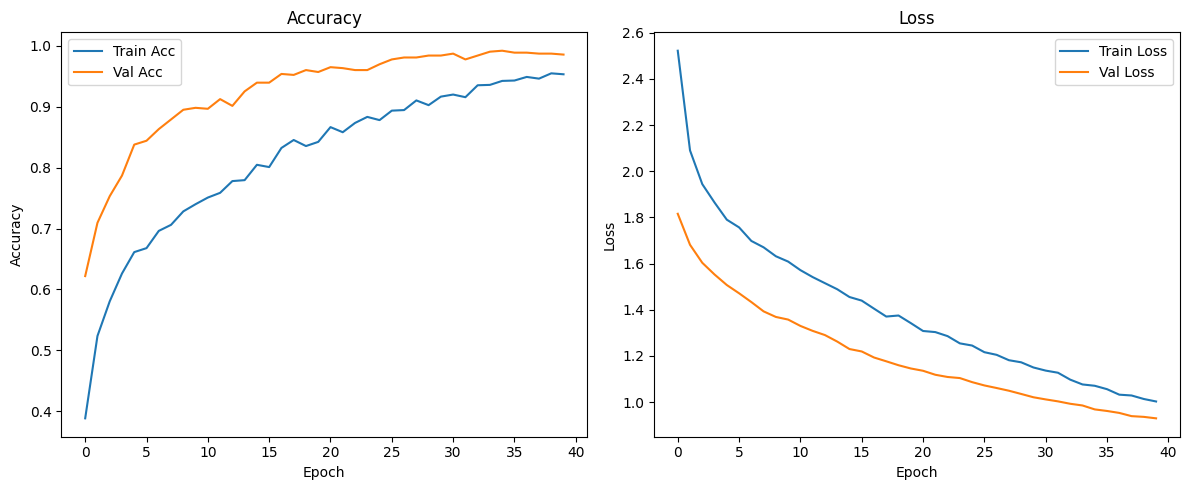

In [ ]:
# Plot training history
def plot_history(history):
    plt.figure(figsize=(12, 5))

    # Accuracy
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Acc')
    plt.plot(history.history['val_accuracy'], label='Val Acc')
    plt.title('Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title('Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.tight_layout()
    plt.show()

plot_history(history)


In [ ]:
test_gen = multimodal_data_generator(test_path, batch_size=BATCH_SIZE)
test_steps = count_images_in_all_stages(test_path) // BATCH_SIZE

# ✅ Evaluate
test_loss, test_acc = model.evaluate(test_gen, steps=test_steps)
print(f"\n✅ Test Accuracy: {test_acc:.4f} | Test Loss: {test_loss:.4f}")

In [ ]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from PIL import Image
import numpy as np
import torch
import os
import cv2
import torch
#from transformers import BlipProcessor, BlipForConditionalGeneration
from transformers import pipeline
import torch.nn as nn
from torch.utils.data import DataLoader
import torchvision.transforms as T
from torchvision.utils import save_image
from tqdm import tqdm
from collections import Counter
from skimage.feature import graycomatrix, graycoprops

def predict_image_updated(image_path, keras_model, stage_label_map=None,verbose=True):
    """
    Predict severity stage for a single image using the trained multimodal model.
    Dynamically computes the lesion mask and description features.
    """

    # 1️⃣ Preprocess image for MobileNetV2
    img = load_img(image_path, target_size=(224, 224))
    img_array = img_to_array(img) / 255.0
    img_tensor = np.expand_dims(img_array, axis=0)  # Shape: (1, 224, 224, 3)

    # 2️⃣ Leaf mask using UNet
    leaf_mask = predict_leaf2(image_path)

    # 3️⃣ Lesion mask + percentage
    original_image = Image.open(image_path).convert("RGB")
    lesion_percentage, lesion_mask = estimate_lesion_size2(original_image, leaf_mask, return_mask=True)

    # 4️⃣ Resize lesion mask to 16×16 and flatten to match training shape
    lesion_mask_resized = cv2.resize(lesion_mask, (16, 16), interpolation=cv2.INTER_AREA)
    lesion_mask_feat = lesion_mask_resized.flatten().astype(np.float32) / 255.0  # Shape: (256,)

    # 5️⃣ Extract description features
    dominant_color = detect_lesion_color_from_image(original_image, lesion_mask)
    gray_img = np.array(original_image.convert("L"))
    contrast, homogeneity, energy, correlation = extract_texture_features(gray_img, lesion_mask)
    r_mean, g_mean, b_mean, r_std, g_std, b_std, h_mean, s_mean = extract_color_stats(original_image, lesion_mask)

    desc_vector = np.array([
        lesion_percentage,
        energy,
        homogeneity,
        h_mean,
        correlation,
        dominant_color
    ], dtype=np.float32).reshape(1, -1)  # Shape: (1, 6)



    # 6️⃣ Run prediction
    y_pred = keras_model.predict([
        img_tensor,
        lesion_mask_feat.reshape(1, -1),  # Shape: (1, 256)
        desc_vector                        # Shape: (1, 6)
    ])
    predicted_class = np.argmax(y_pred, axis=1)[0]
    predicted_stage = stage_label_map[predicted_class] if stage_label_map else f"Stage_{predicted_class + 1}"
    if verbose:

        print(f"✅ Predicted Severity Stage: {predicted_stage}")
    return predicted_stage

In [ ]:
# Map index to human-readable labels (optional)
stage_map = {0: "Stage_1", 1: "Stage_2", 2: "Stage_3", 3: "Stage_4", 4: "Stage_5"}

# Run prediction
predict_image_updated(
    image_path="Dataset/train/Stage_2/images/BACTERAILBLIGHT3_004_aug2.jpg",
    keras_model=model,
    stage_label_map=stage_map
)


In [ ]:
import os
import time
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

def evaluate_inference_time_on_folder(folder_path, keras_model, stage_label_map):
    image_files = [f for f in os.listdir(folder_path) if f.endswith(('.jpg', '.png'))]
    times = []

    for image_file in image_files:
        image_path = os.path.join(folder_path, image_file)

        # ⏱️ Start timer
        start = time.time()

        # 👇 Predict single image
        prediction = predict_image_updated(
            image_path=image_path,
            keras_model=keras_model,
            stage_label_map=stage_label_map,
            verbose=False  # suppress print during batch
        )

        # ⏱️ End timer
        end = time.time()
        inference_time = (end - start) * 1000  # ms
        times.append(inference_time)

    # 📊 Summary
    times = np.array(times)
    print(f"\n✅ Average Inference Time per Image: {times.mean():.2f} ms")
    print(f"📉 Standard Deviation: {times.std():.2f} ms")
    print(f"📦 Tested on {len(image_files)} images.")



In [ ]:

# Load model with CBAM (ensure 'CBAM' class is imported)
import tensorflow.keras as keras  # ✅ Add this if missing
from keras.models import load_model

# Load CBAM model
model = keras.models.load_model('second_best_cbam_multimodal_model.keras',
    custom_objects={'CBAM': CBAM}
)
# Map index to human-readable labels (optional)
stage_map = {0: "Stage_1", 1: "Stage_2", 2: "Stage_3", 3: "Stage_4", 4: "Stage_5"}

evaluate_inference_time_on_folder(
    folder_path="data/Sample_Test_set",
    keras_model=model,
    stage_label_map=stage_map
)


In [ ]:
import os
import time
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array

def dummy_predict_from_folder(model, folder_path):
    times = []

    # List of image files (jpg/png)
    image_files = [f for f in os.listdir(folder_path) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    image_paths = [os.path.join(folder_path, f) for f in image_files]

    print(f"📂 Found {len(image_paths)} images in folder.")

    for img_path in image_paths:
        # Load and preprocess image
        img = load_img(img_path, target_size=(224, 224))
        img_array = img_to_array(img) / 255.0
        img_tensor = np.expand_dims(img_array, axis=0)

        # Dummy mask and description vectors
        mask_feat = np.zeros((1, 256), dtype=np.float32)
        desc_feat = np.zeros((1, 6), dtype=np.float32)

        # Time inference
        start = time.time()
        _ = model.predict([img_tensor, mask_feat, desc_feat], verbose=0)
        end = time.time()

        times.append(end - start)

    # Report results
    print("✅ Average Inference Time per Image: {:.2f} ms".format(np.mean(times) * 1000))
    print("📉 Standard Deviation: {:.2f} ms".format(np.std(times) * 1000))
    print(f"📦 Tested on {len(image_paths)} images.")


model = keras.models.load_model(
    'second_best_cbam_multimodal_model.keras',
    custom_objects={'CBAM': CBAM}
)

dummy_predict_from_folder(
    folder_path="/Users/sudheshkm/2024-phd/data/Sample_Test_set",
    model=model
)

📂 Found 5 images in folder.
✅ Average Inference Time per Image: 233.76 ms
📉 Standard Deviation: 319.42 ms
📦 Tested on 5 images.


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# --- Step 1: Predict all test samples
y_true = []
y_pred = []

# Reset generator
test_gen = multimodal_data_generator(test_path, batch_size=1)
for i in range(count_images_in_all_stages(test_path)):
    batch = next(test_gen)
    inputs, labels = batch
    preds = model.predict(inputs, verbose=0)

    y_true.append(np.argmax(labels, axis=1)[0])
    y_pred.append(np.argmax(preds, axis=1)[0])


In [ ]:
# --- Step 2: Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
class_names = ["Stage_1", "Stage_2", "Stage_3", "Stage_4", "Stage_5"]

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("📊 Confusion Matrix - Multimodal CBAM Classifier")
plt.show()


In [ ]:
def build_multimodal_cbam_model(mask_feat_shape=256, desc_feat_shape=0, freeze_backbone=True):
    img_input = Input(shape=IMAGE_SHAPE, name='image_input')

    base_model = MobileNetV2(include_top=False, weights='imagenet', input_shape=IMAGE_SHAPE)
    if freeze_backbone:
        for layer in base_model.layers:
            layer.trainable = False

    x = base_model(img_input)
    x = CBAM()(x)
    x = GlobalAveragePooling2D()(x)
    x = Dropout(0.4)(x)
    x = BatchNormalization()(x)

    mask_input = Input(shape=(mask_feat_shape,), name='mask_feature_input')
    mask_feat = Dense(128, activation='relu')(mask_input)
    mask_feat = BatchNormalization()(mask_feat)
    mask_feat = Dropout(0.3)(mask_feat)

    inputs = [img_input, mask_input]
    concat_inputs = [x, mask_feat]

    if desc_feat_shape > 0:
        desc_input = Input(shape=(desc_feat_shape,), name='desc_feature_input')
        desc_feat = Dense(64, activation='relu')(desc_input)
        desc_feat = BatchNormalization()(desc_feat)
        desc_feat = Dropout(0.2)(desc_feat)
        inputs.append(desc_input)
        concat_inputs.append(desc_feat)

    merged = Concatenate()(concat_inputs)
    fc = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(merged)
    fc = BatchNormalization()(fc)
    fc = Dropout(0.5)(fc)
    fc = Dense(128, activation='relu')(fc)
    output = Dense(5, activation='softmax')(fc)

    model = Model(inputs=inputs, outputs=output)
    loss_fn = tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1)
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                  loss=loss_fn,
                  metrics=['accuracy'])
    return model


In [ ]:
model_no_desc = build_multimodal_cbam_model(
    mask_feat_shape=256,
    desc_feat_shape=0,      # 🚫 No description
    freeze_backbone=True
)


In [ ]:
def multimodal_data_generator2(data_dir, batch_size=16, shuffle=False, use_description=False):
    image_paths = []
    for stage_folder in sorted(os.listdir(data_dir)):
        if stage_folder.startswith('.'):
            continue
        stage_path = os.path.join(data_dir, stage_folder, "images")
        if not os.path.isdir(stage_path):
            continue
        for img_file in os.listdir(stage_path):
            if img_file.endswith(".jpg") or img_file.endswith(".png"):
                image_paths.append(os.path.join(stage_path, img_file))

    if shuffle:
        np.random.shuffle(image_paths)

    while True:
        for i in range(0, len(image_paths), batch_size):
            batch_imgs, batch_masks, batch_desc, batch_labels = [], [], [], []

            for img_path in image_paths[i:i + batch_size]:
                try:
                    # Load image
                    img = Image.open(img_path).convert("RGB").resize((224, 224))
                    img = np.array(img) / 255.0

                    # Load corresponding mask
                    base_name = os.path.splitext(os.path.basename(img_path))[0]
                    mask_filename = base_name + "_mask.png"
                    mask_path = img_path.replace("/images/", "/masks/")
                    mask_path = os.path.join(os.path.dirname(mask_path), mask_filename)

                    mask = Image.open(mask_path).convert("L").resize((16, 16))
                    mask = np.array(mask).astype(np.float32) / 255.0
                    mask = np.nan_to_num(mask, nan=0.0, posinf=0.0, neginf=0.0)

                    if np.sum(mask) == 0 or np.isnan(mask).any() or np.isinf(mask).any():
                        print(f"⚠️ Skipping empty or invalid mask: {mask_path}")
                        continue

                    mask_vec = mask.flatten()

                    # Optional: load description vector
                    desc_vec = None
                    if use_description:
                        filename = os.path.basename(img_path)
                        desc_vec = desc_dict.get(filename, np.zeros((5,), dtype=np.float32))

                    # Get label
                    stage_folder = img_path.split("/")[-3]
                    label = get_label_from_stage(stage_folder)

                    # Append
                    batch_imgs.append(img)
                    batch_masks.append(mask_vec)
                    batch_labels.append(label)
                    if use_description:
                        batch_desc.append(desc_vec)

                except Exception as e:
                    print(f"❌ Error loading data: {img_path} — {e}")
                    continue

            if not batch_imgs:
                continue

            inputs = {
                "image_input": np.array(batch_imgs),
                "mask_feature_input": np.array(batch_masks)
            }

            if use_description:
                inputs["desc_feature_input"] = np.array(batch_desc)

            yield (inputs, np.array(batch_labels))


In [ ]:
test_gen = multimodal_data_generator2(test_path, batch_size=BATCH_SIZE)
test_steps = count_images_in_all_stages(test_path) // BATCH_SIZE

# ✅ Evaluate
test_loss, test_acc = model.evaluate(test_gen, steps=test_steps)
print(f"\n✅ Test Accuracy: {test_acc:.4f} | Test Loss: {test_loss:.4f}")

In [ ]:
model = build_multimodal_cbam_model(
    mask_feat_shape=256,
    desc_feat_shape=0,      # 🚫 No description
    freeze_backbone=True
)


ROC Curve

2025-12-17 10:32:31.838364: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


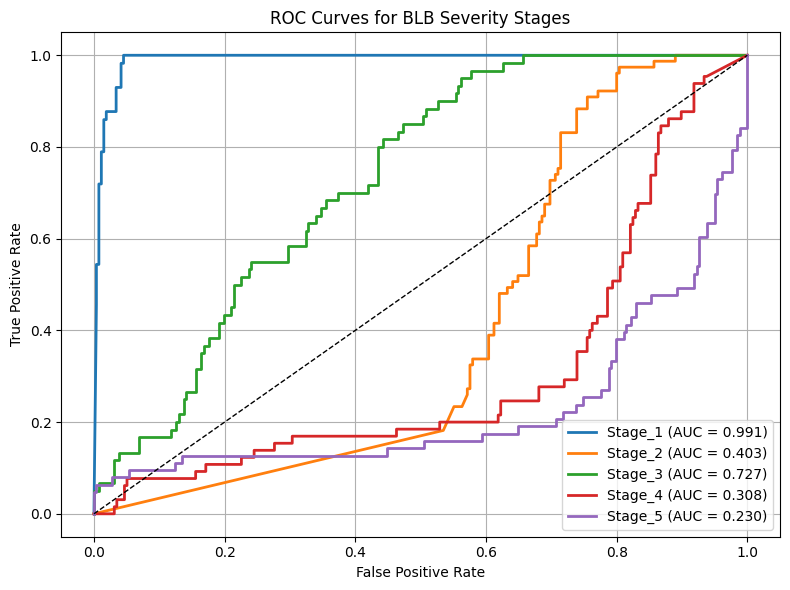

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize

# Class names
class_names = ["Stage_1", "Stage_2", "Stage_3", "Stage_4", "Stage_5"]
n_classes = 5

# Collect predictions
y_true = []
y_score = []


test_path="Dataset/test"
test_gen = multimodal_data_generator(test_path, batch_size=1)

for _ in range(count_images_in_all_stages(test_path)):
    inputs, labels = next(test_gen)
    preds = model.predict(inputs, verbose=0)

    y_true.append(np.argmax(labels, axis=1)[0])
    y_score.append(preds[0])

y_true = np.array(y_true)
y_score = np.array(y_score)

# Binarize labels
y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))

# Plot ROC curves
plt.figure(figsize=(8, 6))

for i in range(n_classes):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=2, label=f"{class_names[i]} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for BLB Severity Stages")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.show()
